In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

print("TensorFlow version:", tf.__version__)

# Load MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize pixel values between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension for CNN
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)


TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)


In [2]:

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:

history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9017 - loss: 0.3253 - val_accuracy: 0.9808 - val_loss: 0.0652
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - accuracy: 0.9699 - loss: 0.0997 - val_accuracy: 0.9838 - val_loss: 0.0510
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 102ms/step - accuracy: 0.9776 - loss: 0.0755 - val_accuracy: 0.9883 - val_loss: 0.0378


Test Accuracy: 98.89%


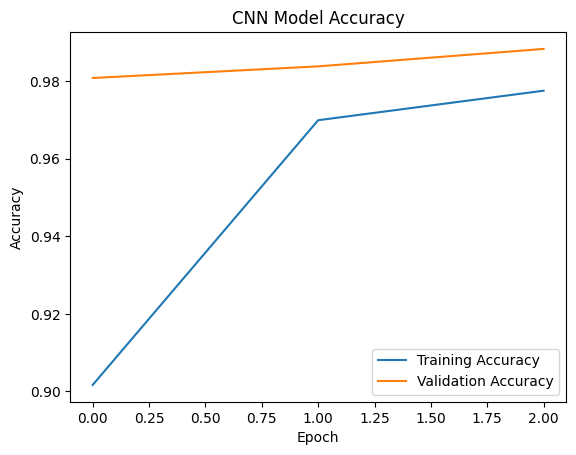

In [4]:

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Model Accuracy")
plt.legend()
plt.show()


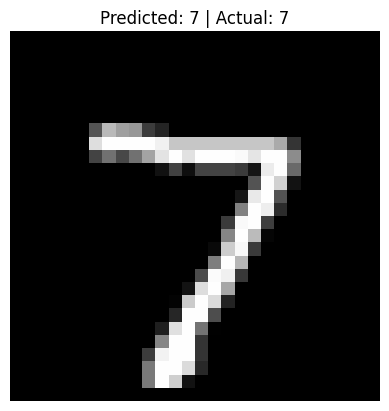

Predicted digit: 7
Actual digit: 7


In [5]:

index = 0

image = x_test[index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)
predicted_digit = np.argmax(prediction)

plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | Actual: {y_test[index]}"
)
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[index])
